In [2]:
import numpy as np
import os
from volta.paths import RESULT_ROOT
from volta.plotting import *
# 1. Define where to look
folder_name = f"{RESULT_ROOT}/data"
file_name_1 = "desired_wrench_hydro.npz"
file_name_2 = "desired_wrench_point.npz"
full_path_1 = os.path.join(folder_name, file_name_1)
full_path_2 = os.path.join(folder_name, file_name_2)
# 2. Load the file
try:
    loaded_data_1 = np.load(full_path_1)
    loaded_data_2 = np.load(full_path_2)

except FileNotFoundError:
    print(f"Error: The file was not found.")

In [4]:
# print("Keys found in file:", loaded_data_1.files)
# 3. Extract the data back into variables
# Note: Use the same string keys used in the save function
timestamp:np.ndarray                = loaded_data_1['timestamp']
desired_wrench_hydro = loaded_data_1['desired_foot_wrenchs']
desired_wrench_point = loaded_data_2['desired_foot_wrenchs']

In [7]:
desired_wrench_hydro.shape

(12, 3071)

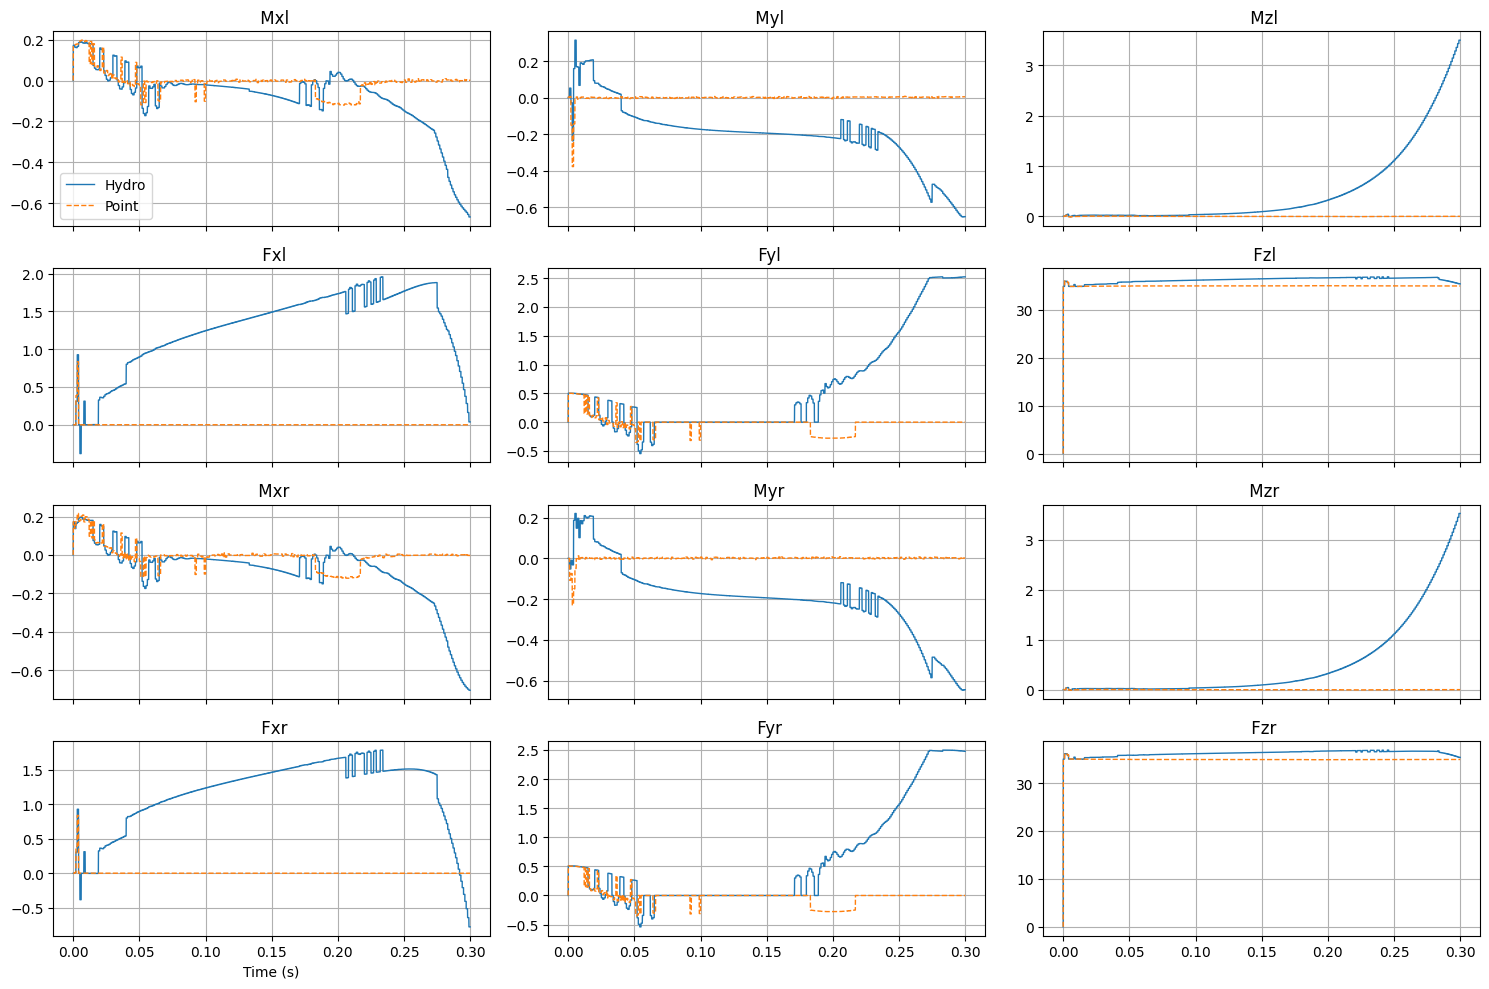

In [9]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(4, 3, figsize=(15, 10), sharex=True)
titles = ['Mxl', 'Myl', 'Mzl', 'Fxl', 'Fyl', 'Fzl', 'Mxr', 'Myr', 'Mzr', 'Fxr', 'Fyr', 'Fzr']
for i, ax in enumerate(axs.flat):
    ax.plot(timestamp, desired_wrench_hydro[i, :], label='Hydro', linewidth=1)
    ax.plot(timestamp, desired_wrench_point[i, :], label='Point', linestyle='--', linewidth=1)
    ax.set_title(f' {titles[i]}')
    ax.grid(True)
    if i == 0:
        ax.legend()

axs[-1, 0].set_xlabel('Time (s)')
plt.tight_layout()
plt.show()